TensorFlow Version: 2.21.0

Dataset Loaded Successfully!
Training samples: 25000
Testing samples: 25000

Training Labels:
Negative: 12500
Positive: 12500

Testing Labels:
Negative: 12500
Positive: 12500

After Padding:
Training shape: (25000, 200)
Testing shape: (25000, 200)

Model Summary:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 167s 528ms/step - accuracy: 0.5333 - loss: 0.6887 - val_accuracy: 0.5444 - val_loss: 0.6806
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 205s 538ms/step - accuracy: 0.5678 - loss: 0.6825 - val_accuracy: 0.5236 - val_loss: 0.6894
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 153s 490ms/step - accuracy: 0.6219 - loss: 0.6316 - val_accuracy: 0.7760 - val_loss: 0.5132
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 156s 499ms/step - accuracy: 0.8245 - loss: 0.4220 - val_accuracy: 0.8270 - val_loss: 0.4105
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 156s 500ms/step - accuracy: 0.8896 - loss: 0.2879 - val_accuracy: 0.8480 - val_loss: 0.3749

MODEL PERFORMANCE
Test Loss: 0.3994
Test Accuracy: 83.62 %

EVALUATION METRICS
Accuracy : 83.62 %
Precision: 87.15 %
Recall   : 78.86 %
F1 Score : 82.8 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.88      0.84     12500
    Positive       0.87      0.79      0.83     12500

  

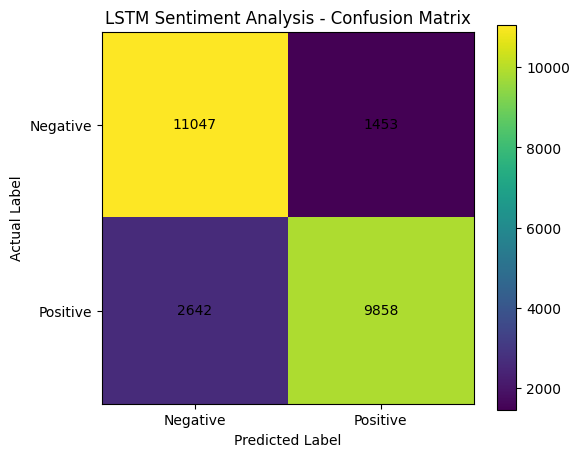

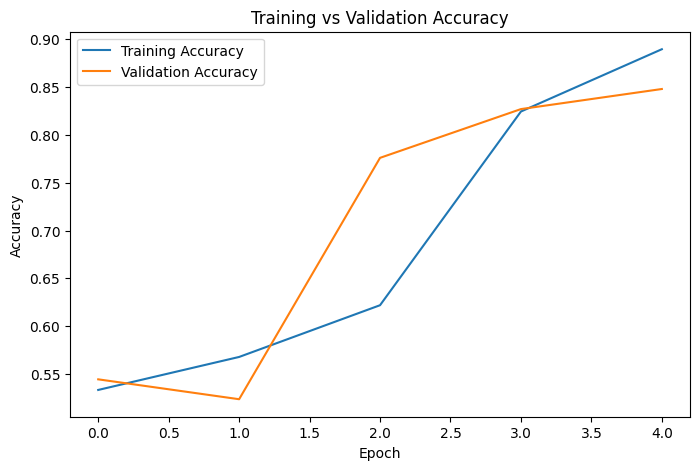

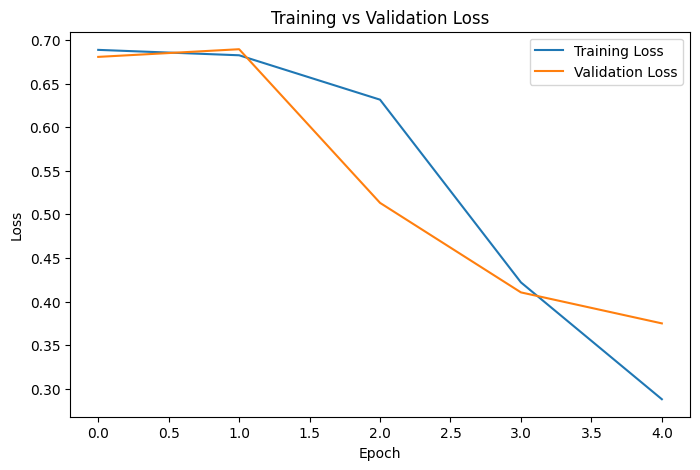

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

SENTIMENT PREDICTION
Review: This movie was amazing and the acting was excellent
Prediction: POSITIVE
Confidence: 94.84 %

SENTIMENT PREDICTION
Review: The movie was boring and the story was terrible
Prediction: NEGATIVE
Confidence: 94.72 %

Model saved as: movie_sentiment_lstm.keras


In [3]:
# ============================================================
# MOVIE REVIEW SENTIMENT ANALYSIS USING LSTM
# NLP + DEEP LEARNING PROJECT
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)


# ============================================================
# 2. LOAD IMDB DATASET
# ============================================================

vocab_size = 10000

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("\nDataset Loaded Successfully!")
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))


# ============================================================
# 3. CHECK LABEL DISTRIBUTION
# ============================================================

print("\nTraining Labels:")
print("Negative:", np.sum(y_train == 0))
print("Positive:", np.sum(y_train == 1))

print("\nTesting Labels:")
print("Negative:", np.sum(y_test == 0))
print("Positive:", np.sum(y_test == 1))


# ============================================================
# 4. PADDING
# ============================================================

max_length = 200

x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("\nAfter Padding:")
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)


# ============================================================
# 5. BUILD LSTM MODEL
# ============================================================

model = Sequential()

# Converts word IDs into dense vectors
model.add(
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        input_length=max_length
    )
)

# LSTM learns patterns in the sequence of words
model.add(
    LSTM(128)
)

# Helps reduce overfitting
model.add(
    Dropout(0.5)
)

# Binary classification
model.add(
    Dense(1, activation="sigmoid")
)


# ============================================================
# 6. COMPILE MODEL
# ============================================================

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nModel Summary:")
model.summary()


# ============================================================
# 7. TRAIN MODEL
# ============================================================

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


# ============================================================
# 8. EVALUATE MODEL
# ============================================================

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("\n===================================")
print("MODEL PERFORMANCE")
print("===================================")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


# ============================================================
# 9. MAKE PREDICTIONS
# ============================================================

y_probability = model.predict(
    x_test,
    verbose=0
)

y_pred = (y_probability >= 0.5).astype(int).flatten()


# ============================================================
# 10. CALCULATE METRICS
# ============================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\n===================================")
print("EVALUATION METRICS")
print("===================================")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")


# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("LSTM Sentiment Analysis - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()


# ============================================================
# 13. TRAINING & VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()


# ============================================================
# 14. TRAINING & VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()


# ============================================================
# 15. CREATE WORD INDEX
# ============================================================

word_index = imdb.get_word_index()

# IMDB reserves the first few indexes
word_index = {
    word: index + 3
    for word, index in word_index.items()
}

word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2


# ============================================================
# 16. FUNCTION TO CONVERT TEXT TO NUMBERS
# ============================================================

def encode_review(text):

    words = text.lower().split()

    encoded = []

    for word in words:

        if word in word_index:
            index = word_index[word]

            if index < vocab_size:
                encoded.append(index)
            else:
                encoded.append(2)

        else:
            encoded.append(2)

    return encoded


# ============================================================
# 17. FUNCTION TO PREDICT SENTIMENT
# ============================================================

def predict_sentiment(review):

    encoded_review = encode_review(review)

    padded_review = pad_sequences(
        [encoded_review],
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probability = model.predict(
        padded_review,
        verbose=0
    )[0][0]

    if probability >= 0.5:

        sentiment = "POSITIVE"

        confidence = probability * 100

    else:

        sentiment = "NEGATIVE"

        confidence = (1 - probability) * 100

    print("\n===================================")
    print("SENTIMENT PREDICTION")
    print("===================================")
    print("Review:", review)
    print("Prediction:", sentiment)
    print("Confidence:", round(confidence, 2), "%")


# ============================================================
# 18. TEST YOUR OWN REVIEWS
# ============================================================

predict_sentiment(
    "This movie was amazing and the acting was excellent"
)

predict_sentiment(
    "The movie was boring and the story was terrible"
)


# ============================================================
# 19. SAVE MODEL
# ============================================================

model.save("movie_sentiment_lstm.keras")

print("\nModel saved as: movie_sentiment_lstm.keras")

In [5]:
!pip install -q streamlit pyngrok

In [6]:
%%writefile app.py

import streamlit as st
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb


# ==============================
# PAGE SETTINGS
# ==============================

st.set_page_config(
    page_title="Movie Review Sentiment AI",
    page_icon="🎬",
    layout="centered"
)


# ==============================
# LOAD TRAINED MODEL
# ==============================

model = tf.keras.models.load_model(
    "movie_sentiment_lstm.keras"
)

vocab_size = 10000
max_length = 200


# ==============================
# LOAD IMDB WORD INDEX
# ==============================

word_index = imdb.get_word_index()

word_index = {
    word: index + 3
    for word, index in word_index.items()
}

word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2


# ==============================
# CONVERT REVIEW TO NUMBERS
# ==============================

def encode_review(text):

    words = text.lower().split()

    encoded = []

    for word in words:

        if word in word_index:

            index = word_index[word]

            if index < vocab_size:
                encoded.append(index)
            else:
                encoded.append(2)

        else:
            encoded.append(2)

    return encoded


# ==============================
# PREDICT SENTIMENT
# ==============================

def predict_sentiment(text):

    encoded = encode_review(text)

    padded = pad_sequences(
        [encoded],
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probability = model.predict(
        padded,
        verbose=0
    )[0][0]

    if probability >= 0.5:

        sentiment = "Positive 😊"
        confidence = probability * 100

    else:

        sentiment = "Negative 😞"
        confidence = (1 - probability) * 100

    return sentiment, confidence


# ==============================
# WEBSITE UI
# ==============================

st.title("🎬 Movie Review Sentiment AI")

st.write(
    "Enter a movie review and the LSTM model "
    "will predict whether the sentiment is positive or negative."
)

st.divider()


review = st.text_area(
    "Enter your movie review:",
    placeholder="Example: The movie was amazing and the acting was excellent!",
    height=150
)


if st.button(
    "🔍 Analyze Review",
    use_container_width=True
):

    if review.strip() == "":

        st.warning("Please enter a movie review.")

    else:

        sentiment, confidence = predict_sentiment(review)

        st.subheader("Prediction")

        if "Positive" in sentiment:

            st.success(sentiment)

        else:

            st.error(sentiment)

        st.metric(
            "Confidence",
            f"{confidence:.2f}%"
        )

        st.progress(
            int(confidence)
        )


st.divider()

st.subheader("About the Model")

st.write(
    """
    This application uses Natural Language Processing
    and a Long Short-Term Memory (LSTM) neural network
    to classify movie reviews as positive or negative.
    """
)

st.info(
    "Model: Embedding + LSTM + Dropout + Dense"
)

Writing app.py


In [7]:
!streamlit run app.py &> /content/streamlit.log &

In [8]:
!cat /content/streamlit.log



2026-10-14 16:03:53.796 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.129.65:8501

